# Classifying Tomato Leaf Diseases

## By Lohen Richard Chamberlain
---
## Loading data

The dataset I used has 10000 images for 10 different states of tomato leaves for training, and 1000 images per state for validation.

Each image is initailly 256 by 256, but we shrink the image to 160 by 160 pixels. I found that 128 was too small and 160 is a nice middleground.

## Batching

Batching makes it easier on the GPU. Batching is like saying I want 32 vanill a icecreams in stead of saying: one vanilla icecream, one vanilla icecream, one vanilla icream ect.

Batch sizes of 32 is ideal, because GPU likes numbers which are powers of two, and 32 is small enough to be handeled easily.

In [3]:
import tensorflow as tf

train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "data/tomato/train",
    image_size=(160,160),
    batch_size=32
)

val_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "data/tomato/val",
    image_size=(160,160),
    batch_size=32
)

Found 10000 files belonging to 10 classes.


I0000 00:00:1780759732.603822    1015 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 1000 files belonging to 10 classes.


## Classes
Here we check the class names so that we can check they are as expected.

We also check the number of classes so that we can set up our model's output layer correctly.    

In [4]:
class_names = train_dataset.class_names
num_classes = len(class_names)
for i in range(len(class_names)):
    print(str(i + 1) + ')' + class_names[i][9:])

1)Bacterial_spot
2)Early_blight
3)Late_blight
4)Leaf_Mold
5)Septoria_leaf_spot
6)Spider_mites Two-spotted_spider_mite
7)Target_Spot
8)Tomato_Yellow_Leaf_Curl_Virus
9)Tomato_mosaic_virus
10)healthy


## Prefetching

This part is my favourite little thing. It fetches the next set of data while the GPU handles the previous set.

This is like deciding what to order before getting to the front of the macdonalds queue, so the cashier does not have to wait for you to decide.

The data is ready for the GPU to use and it does not have to wait after each batch for the nect one to be fetched.

In [5]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(AUTOTUNE)
val_dataset = val_dataset.prefetch(AUTOTUNE)

## Augmentation

I removed it, but it is too cool to not be mentioned. It turns and zooms each image randomly so you get more image, **per image**.

I did remove it from the model itself though since the model performed worse due to the loss of consistent lightling and presentaion which lowers the quality of the sample.

In [6]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.05),
])

## Model architexture

### Rescale
We first rescale the layers to be between 1 and 0 so as to be nice, consistent and Predictionictionictable for the model.

### CNN
We then put convolutional layers to extract features from the images. These are the one with the little matrices that move across the image.

These layers find:

1) Edges
2) Shapes
3) More complex features
4) ...

### Pooling
Then we have pooling layers to reduce the size of the image and in doing so, the computation in the model.

We then flatten the output with global pooling. This minimizes parameters to reduce overfitting, enhances computational efficiency (thanks stack overflow).

### Dropout
We have 30% dropout, which means we switch 30% of neurons off randomly each epoch so that the moedel doesn't rely on one key neuron.

### Dense layers
We have a dense layer with 128 neurons.
Finally we have a dense layer with 10 neurons (one for each class).

It uses softmax to get the probability of each class being the correct result. It then chooses the most likely result.

In [7]:
model = tf.keras.Sequential([
tf.keras.layers.Input(shape=(160, 160, 3)),#t
tf.keras.layers.Rescaling(1./255),

tf.keras.layers.Conv2D(32, 3, use_bias=False),
tf.keras.layers.BatchNormalization(),
tf.keras.layers.Activation('relu'),
tf.keras.layers.MaxPooling2D(),

tf.keras.layers.Conv2D(64, 3, use_bias=False),
tf.keras.layers.BatchNormalization(),
tf.keras.layers.Activation('relu'),
tf.keras.layers.MaxPooling2D(),

tf.keras.layers.Conv2D(128, 3, use_bias=False),
tf.keras.layers.BatchNormalization(),
tf.keras.layers.Activation('relu'),
tf.keras.layers.MaxPooling2D(),

tf.keras.layers.Conv2D(256, 3, use_bias=False),
tf.keras.layers.BatchNormalization(),
tf.keras.layers.Activation('relu'),

tf.keras.layers.GlobalAveragePooling2D(),

tf.keras.layers.Dropout(0.3),

tf.keras.layers.Dense(128, activation='relu'),
tf.keras.layers.Dense(num_classes, activation='softmax')])

## Compiling
- We use the adam optimiser.

- We use sparse categorical crossentrop.

- We use accuracy as our metric.

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Learning Rate Scheduler

Something about slowing it based on how much it changes. 

Basically it adapts to ho w fast your model is changing for peak effeciency.

Source: trust me bro.

In [9]:
lr_schedule = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=3
)

## Training

This is where the magic happens. We run it for 30 epochs (rounds), since that is what I found to work best.

Less epochs doesn't gice it the chance to converge with the training data's accuracy properly.

More epochs risks overfitting.

In [10]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[lr_schedule]
)

Epoch 1/30


I0000 00:00:1780759740.575041    1670 service.cc:153] XLA service 0x76044c038640 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1780759740.575113    1670 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.20.0)
I0000 00:00:1780759740.862752    1670 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1780759741.730912    1670 cuda_dnn.cc:461] Loaded cuDNN version 92000
I0000 00:00:1780759741.896528    1670 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3549__.63
I0000 00:00:1780759747.691969    1670 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set i

311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5693 - loss: 1.2124

I0000 00:00:1780759775.367141    1669 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3549__.63


313/313 ━━━━━━━━━━━━━━━━━━━━ 64s 115ms/step - accuracy: 0.6861 - loss: 0.8929 - val_accuracy: 0.1640 - val_loss: 10.0565 - learning_rate: 0.0010
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.8149 - loss: 0.5331 - val_accuracy: 0.5730 - val_loss: 1.5416 - learning_rate: 0.0010
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.8560 - loss: 0.4234 - val_accuracy: 0.7540 - val_loss: 0.7197 - learning_rate: 0.0010
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8770 - loss: 0.3527 - val_accuracy: 0.6710 - val_loss: 1.1903 - learning_rate: 0.0010
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.8924 - loss: 0.3116 - val_accuracy: 0.8900 - val_loss: 0.3500 - learning_rate: 0.0010
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.9020 - loss: 0.2786 - val_accuracy: 0.5370 - val_loss: 2.6113 - learning_rate: 0.0010
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.9118 - loss: 0.2491

# Previous Graphs

## Naive model

At this point I was trying to model proteins of bacteria. I thought it was interesting and wanted to try it. 

You know how chat gpt is always like: YOU GOT THISS!!!!

Chat said: No thats too complicated. Try use only the overview file. Not the whole dataset.

The first run was abysmal. Each time I retrained the model it had wildly different levels of succes, with no change in setup or parameters.

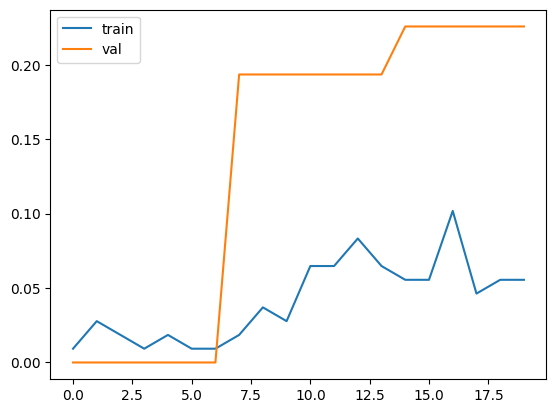
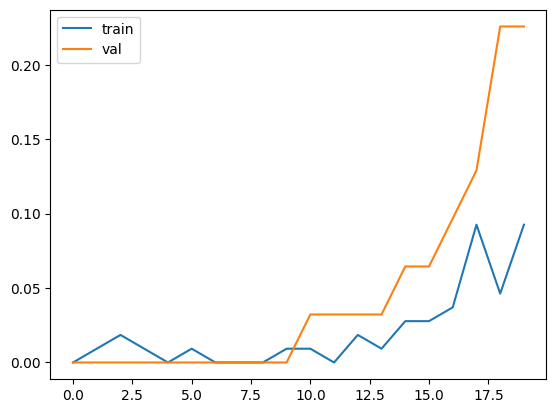
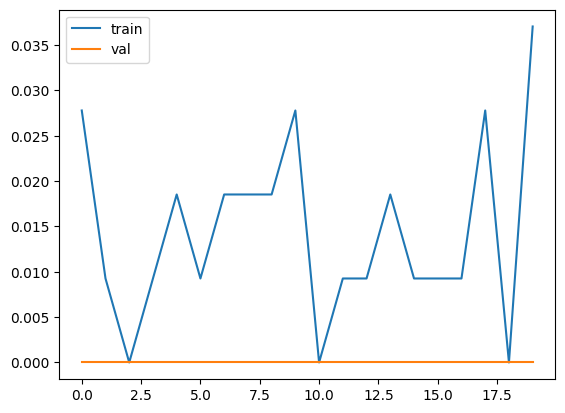
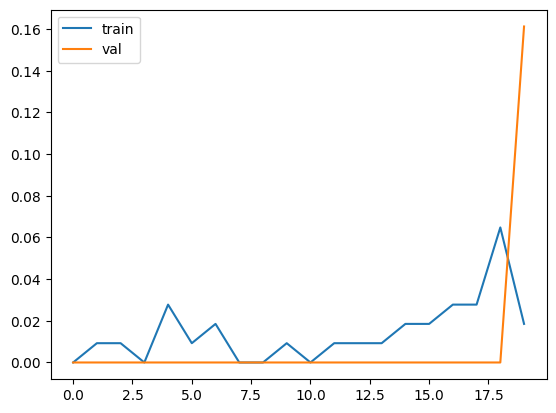
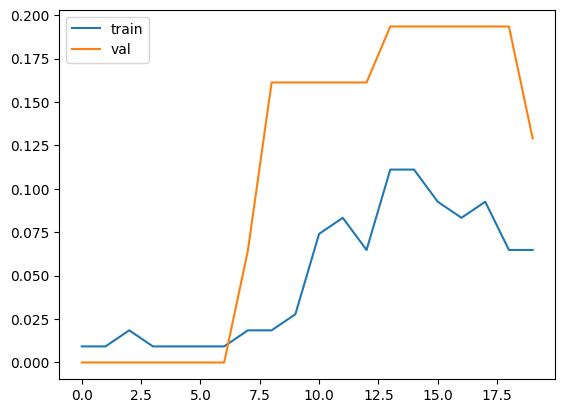

## Less Classes

This is when I realised I only had 320 lines of data, and was trying ot classify 100+ classes.

That is 3 examples per item. Not nearly enough. For example, my current setup has 10000 images.

So I grouped the classes so it classifies them in groups. A tiny bit better. Less erratic, but only about 15% accurate.

Also, if anything ever insists that everything is 18, thats generally not a good sign.

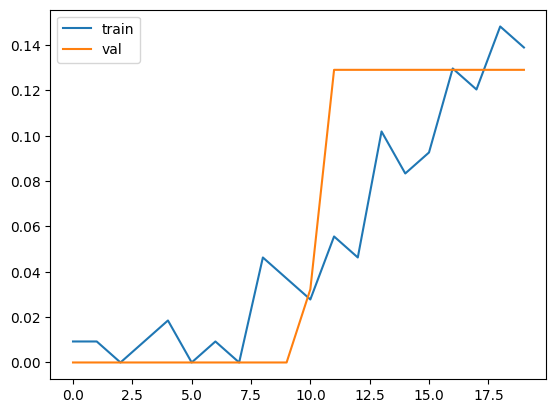
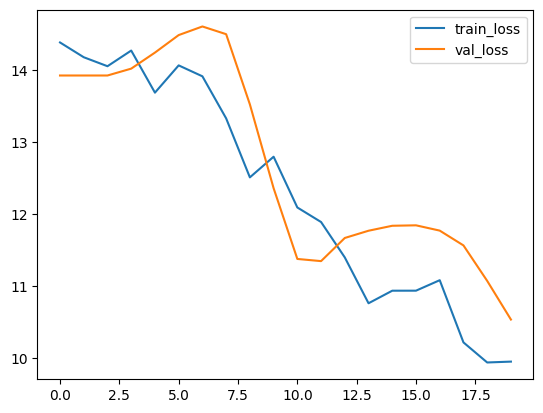
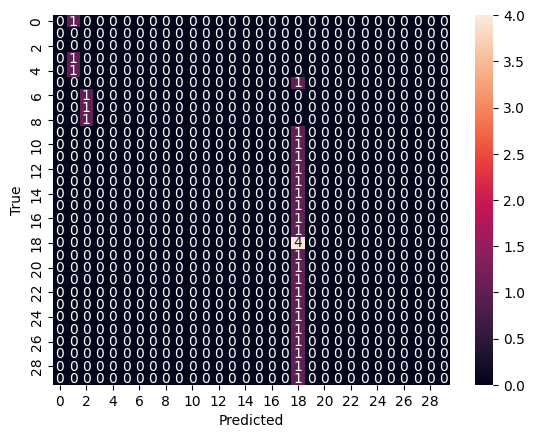

## Tomato Models

Here I swapped to a new dataset out of sheer spite. Imagine my surprise when I got 91% accuracy for repurposing a model archetexture that only got 15% accuracy previously.

The orange one on top is the initial model. Which is frankly insane. I then tested different factors. Graph 1 and 2 show why I choseto remove augmentation.

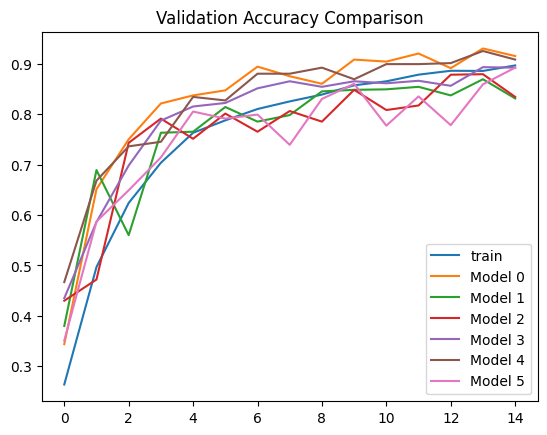

I basically decided to keep the base model and refine it with batch nominalisation.

This worked a treat and with the Learning rate schedular gives you our final product: 98%-99% accuracy!

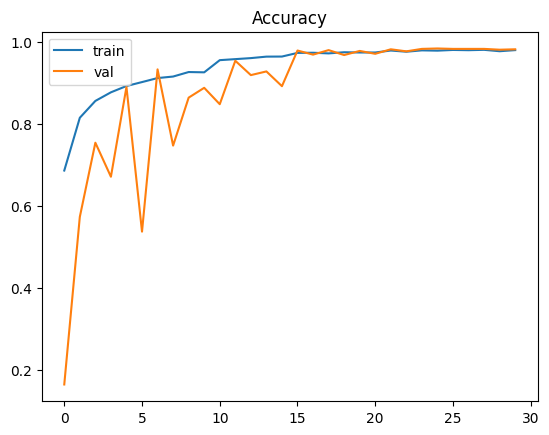

In [11]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title("Accuracy")
plt.show()

# SUCCESS!!!

You can see how the model converges nicely with training. 

The jagged start shows how the first epochs make big changes due to the model learning a lot.

The convergence shows how the last epochs refines the model.

In [12]:
print("Final train acc:" + str(history.history['accuracy'][-1]))
print("Final validation acc:" + str(history.history['val_accuracy'][-1]))

Final train acc:0.9800000190734863
Final validation acc:0.9819999933242798


In [ ]:
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt
from tensorflow.keras.utils import plot_model

IMG_SIZE = (160, 160)

def get_activations(model, input_data):
    layer_outputs = [layer.output for layer in model.layers]
    activation_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=layer_outputs
    )
    return activation_model.predict(input_data)

import seaborn as sns

def plot_activation_distribution(img_array):
    # Get final layer before softmax
    intermediate_model = Model(inputs=model.inputs, outputs=model.layers[-2].output)
    activations = intermediate_model.predict(img_array)

    sns.histplot(activations.flatten(), bins=50, kde=True)
    plt.title("Activation Distribution")
    plt.show()

# ----------------------------
# VISUALISATION
# ----------------------------
def plot_feature_maps(feature_map, max_filters=16):
    fmap = feature_map[0]

    n_filters = min(fmap.shape[-1], max_filters)
    cols = 4
    rows = int(np.ceil(n_filters / cols))

    plt.figure(figsize=(8, 8))

    for i in range(n_filters):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(fmap[:, :, i], cmap="viridis")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

def plot_dense(values, class_names=None, title="Dense Layer"):
    class_names_clean = [name[9:].replace("_", " ") for name in class_names]
    values = np.squeeze(values)

    # normalize (fixed bug)
    values = (values - values.min()) / (values.max() - values.min() + 1e-8)

    plt.figure(figsize=(10, 4))

    if class_names_clean is not None and len(class_names_clean) == len(values):
        plt.bar(class_names_clean, values)
        plt.xticks(rotation=45, ha='right')
    else:
        plt.bar(range(len(values)), values)

    plt.title(title)
    plt.tight_layout()
    plt.show()

def visualize_activations(img_array):
    model.build((None, 160, 160, 3))#t
    layer_outputs = [layer.output for layer in model.layers if 'conv' in layer.name]
    activation_model = Model(inputs=model.inputs, outputs=layer_outputs)

    activations = activation_model.predict(img_array)

    # Plot first few feature maps
    for layer_idx, activation in enumerate(activations[:3]):
        plt.figure(figsize=(10, 4))

        for i in range(min(6, activation.shape[-1])):
            plt.subplot(1, 6, i+1)
            plt.imshow(activation[0, :, :, i], cmap='viridis')
            plt.axis('off')

        plt.suptitle(f"Layer {layer_idx+1} Feature Maps")
        plt.show()

def analyse_image(model, img_array):
    activations = get_activations(model, img_array)
    clear_output(wait=True)

    pred = model.predict(img_array)[0]
    pred_class = np.argmax(pred)

    print("Raw prediction:", pred)

    if class_names:
        print("Prediction:", class_names[pred_class])
    else:
        print("Prediction class index:", pred_class)

    print("Confidence:", pred[pred_class])

    plot_activation_distribution(img_array)

    for layer, act in zip(model.layers, activations):

        if isinstance(layer, tf.keras.layers.Conv2D):
            print(f"\n🧠 {layer.name} (Conv)")
            plot_feature_maps(act)

        elif isinstance(layer, tf.keras.layers.Dense):
            print(f"\n📊 {layer.name} (Dense)")
            plot_dense(act, class_names)


    predicted_class = class_names[np.argmax(pred)]
    confidence = np.max(pred)

    # Show image
    #plt.imshow(img)
    plt.title(f"{predicted_class} ({confidence:.2f})")
    plt.axis('off')
    plt.show()

    #visualize_activations(img_array)
    plot_activation_distribution(img_array)

    # Also print top 3 (optional but nice)
    top_indices = pred.argsort()[-3:][::-1]
    print("\nTop predictions:")
    for i in top_indices:
        print(f"{class_names[i]}: {pred[i]:.2f}")

def predict_and_show(img_array):
    plot_model(
        model,
        to_file="model_structure.png",
        show_shapes=True,
        show_layer_names=True,
        expand_nested=True
    )

    predictions = model.predict(img_array)[0]

    predicted_class = class_names[np.argmax(predictions)]
    confidence = np.max(predictions)

    # Show image
    #plt.imshow(img)
    plt.title(f"{predicted_class} ({confidence:.2f})")
    plt.axis('off')
    plt.show()

    #visualize_activations(img_array)
    plot_activation_distribution(img_array)

    # Also print top 3 (optional but nice)
    top_indices = predictions.argsort()[-3:][::-1]
    print("\nTop predictions:")
    for i in top_indices:
        print(f"{class_names[i]}: {predictions[i]:.2f}")

upload = widgets.FileUpload(accept="image/*", multiple=False)
button = widgets.Button(description="Run CNN Analysis", button_style="success")
out = widgets.Output()

def full_demo(img_path):
    predict_and_show(img_path)
    visualize_activations(img_path)
    plot_activation_distribution(img_path)

def on_click(b):
    with out:
        clear_output(wait=True)

        if not upload.value:
            print("Upload an image first")
            return

        """file = upload.value[0]
        content = bytes(file["content"])

        #img = tf.image.decode_image(content, channels=3)
        #img = image.load_img(file, target_size=(160, 160))
        img = image.load_img('data/tomato/val/Tomato___healthy/0a0d6a11-ddd6-4dac-8469-d5f65af5afca___RS_HL 0555.JPG', target_size=(160, 160))
        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)

        img = tf.cast(img, tf.float32)"""

        file = upload.value[0]
        content = bytes(file["content"])  

        img = tf.image.decode_image(content, channels=3)
        img = tf.image.resize(img, (160, 160))
        img_array = tf.expand_dims(img, axis=0) 
        img_array = tf.cast(img_array, tf.float32)


        plt.imshow(img.numpy().astype("uint8"))
        plt.title("Input Image")
        plt.axis("off")
        plt.show()

        analyse_image(model, img_array)
        #predict_and_show(img_array)

button.on_click(on_click)

display(widgets.VBox([
    widgets.Label("📤 Upload an image"),
    upload,
    button,
    out
]))

In [14]:
import os
print(os.getcwd())

/home/lohen/projects/ml/Machine learning
